# 01. Bronze e Silver: qualidade dos dados e dias atípicos

Este caderno confere a base que alimentará os modelos. Ele responde a três perguntas:

1. A Silver reconstruída preserva os valores das fontes?
2. O que falta nos dados?
3. Quais dias se comportaram fora do padrão, e o que os explica?

A regra de atípicos usa apenas consumos anteriores a cada dia e não usa erro de modelo. **O tipo de cada dia é uma hipótese**: indica a explicação mais provável pelo calendário, não uma causa comprovada. Nenhuma comparação de modelos é feita aqui.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_rows", 80, "display.max_columns", 30, "display.width", 180)
CLAUDE = Path("..")
SILVER = CLAUDE / "dados" / "silver"
FIGURAS = CLAUDE / "resultados" / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)

SUPERFICIE, TEXTO, TEXTO2, GRADE = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e0"
AZUL, LARANJA, AQUA, VIOLETA = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6"
plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "axes.edgecolor": GRADE, "axes.labelcolor": TEXTO2, "xtick.color": TEXTO2, "ytick.color": TEXTO2,
    "text.color": TEXTO, "axes.grid": True, "grid.color": GRADE, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True, "font.size": 10,
})

fato = pd.read_parquet(SILVER / "silver_fato_diaria.parquet")
candidatos = pd.read_parquet(SILVER / "silver_candidatos_atipicos.parquet")
referencia = pd.read_parquet(SILVER / "silver_referencia_consumo.parquet")
manifesto = json.loads((CLAUDE / "dados" / "bronze" / "manifesto.json").read_text(encoding="utf-8"))
print(f"Bronze: {len(manifesto['arquivos'])} arquivos | Silver: {fato.shape[0]} datas, {fato.shape[1]} colunas")

Bronze: 20 arquivos | Silver: 1461 datas, 32 colunas


## 1. Integridade da Silver

Na construção desta base, consumo e planos foram conferidos com a base anterior da pesquisa, sem diferenças.

In [2]:
assert len(fato) == 1461
assert fato["data"].is_unique
assert not (fato["reserva_discente"].notna() & fato["plano_nutricionista"].notna()).any()
print("Uma linha por data; reservas e plano da nutricionista nunca coexistem.")

fato[fato["tem_consumo"]].groupby("ano").agg(
    datas=("consumo", "size"), media=("consumo", "mean"), minimo=("consumo", "min"), maximo=("consumo", "max"),
).round(1)

Uma linha por data; reservas e plano da nutricionista nunca coexistem.


,datas,media,minimo,maximo
ano,,,,
2023,181,107.8,1.0,157.0
2024,149,157.6,27.0,243.0
2025,173,138.0,16.0,216.0
2026,156,170.0,14.0,266.0


## 2. O que falta nos dados

Consumo ausente não é zero. Datas letivas com cardápio ou plano, mas sem consumo, podem ser registro perdido ou dia sem serviço; só a conferência pode separar os dois casos.

In [3]:
escopo = fato[fato["no_escopo"] & (fato["data"] <= "2026-10-30")]
letivos = escopo[escopo["status_legal"].eq("letivo")]
servidos = escopo[escopo["tem_consumo"]]
sem_consumo = pd.read_csv(SILVER / "silver_letivos_sem_consumo.csv", sep=";", encoding="utf-8-sig", parse_dates=["data"])

resumo = pd.Series({
    "dias letivos de segunda a sexta": len(letivos),
    "dias com consumo (segunda a sexta)": len(servidos),
    "dias com consumo fora do calendário letivo": int((servidos["status_legal"] != "letivo").sum()),
    "dias com consumo sem cardápio": int((~servidos["tem_cardapio"]).sum()),
    "dias letivos sem consumo, com cardápio ou plano": len(sem_consumo),
    "sábados com consumo (fora do escopo)": int((fato["tem_consumo"] & ~fato["no_escopo"]).sum()),
})
print(resumo.to_string())
sem_consumo.groupby(sem_consumo["data"].dt.year).agg(dias=("data", "size"), em_periodo_de_greve=("periodo_greve", "sum"))

dias letivos de segunda a sexta                    713
dias com consumo (segunda a sexta)                 656
dias com consumo fora do calendário letivo           8
dias com consumo sem cardápio                       20
dias letivos sem consumo, com cardápio ou plano     56
sábados com consumo (fora do escopo)                 3


,dias,em_periodo_de_greve
data,,
2023,12,0
2024,30,15
2025,10,0
2026,4,0


## 3. Dias fora do padrão

Cada dia é comparado com uma referência calculada só com o passado: a média entre a mediana dos 10 dias normais anteriores e a mediana das 4 últimas ocorrências normais do mesmo dia da semana. A razão `consumo / referência` abaixo de 0,60 aponta um dia baixo; acima de 1,40, um dia alto.

In [4]:
baixos = candidatos[candidatos["direcao"] == "baixo"]
altos = candidatos[candidatos["direcao"] == "alto"]
print(f"Dias avaliados: {referencia['razao_referencia'].notna().sum()} | baixos: {len(baixos)} | altos: {len(altos)}")
print("Mediana da razão:", round(referencia["razao_referencia"].median(), 3))
candidatos.groupby(["direcao", "tipo_sugerido"]).agg(
    dias=("data", "size"), consumo_mediano=("consumo", "median"), razao_mediana=("razao_referencia", "median"),
).round(2)

Dias avaliados: 648 | baixos: 48 | altos: 20
Mediana da razão: 1.002


dias  consumo_mediano  razao_mediana
direcao tipo_sugerido                                                  
alto    evento_de_calendario          1            135.0           1.59
        inicio_de_bloco_letivo        4            197.0           1.51
        isolado_sem_explicacao       15            212.0           1.47
baixo   evento_de_calendario          5             66.0           0.50
        evento_externo_registrado     5             84.0           0.41
        fim_de_bloco_letivo          16             50.5           0.35
        inicio_de_bloco_letivo       11             56.0           0.37
        isolado_sem_explicacao        5             47.0           0.23
        nao_letivo_com_consumo        4             27.5           0.22
        periodo_de_greve              1            104.0           0.50
        sequencia_de_dias             1             44.0           0.37

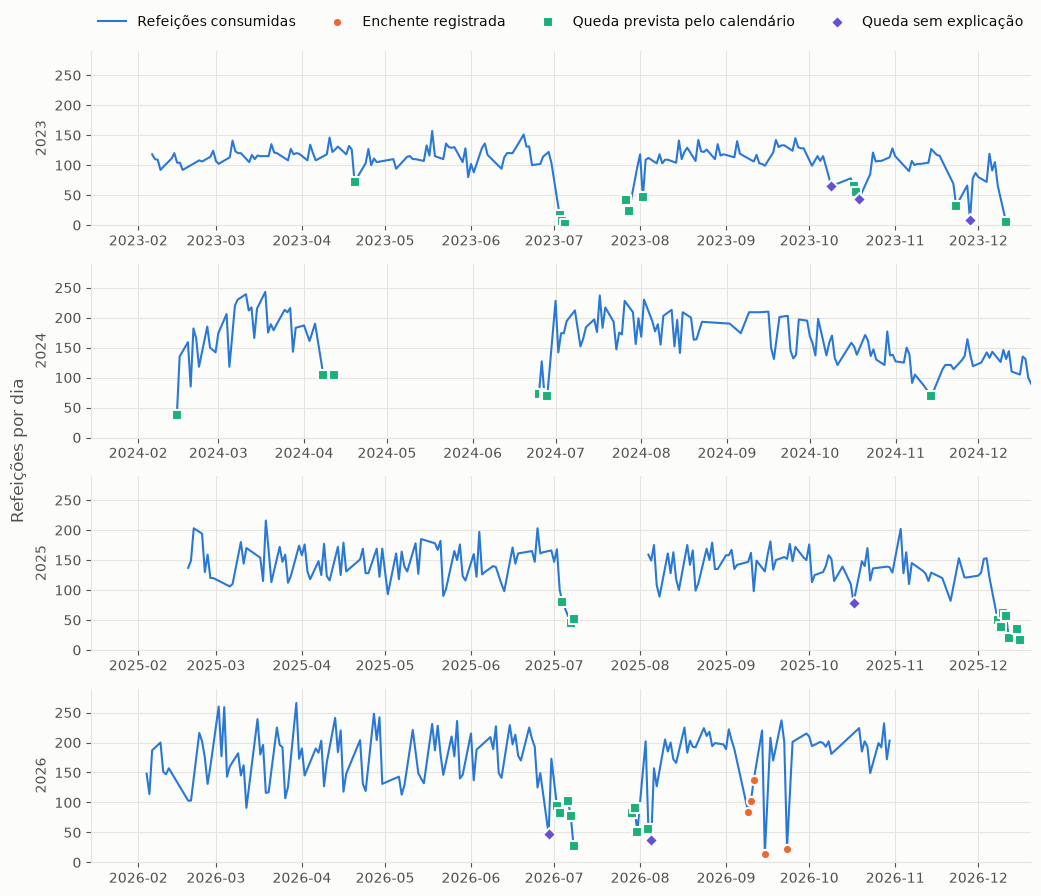

In [5]:
PREVISIVEIS = {"fim_de_bloco_letivo", "inicio_de_bloco_letivo", "evento_de_calendario", "nao_letivo_com_consumo", "periodo_de_greve"}
grupos = [
    ("Enchente registrada", baixos[baixos["tipo_sugerido"] == "evento_externo_registrado"], LARANJA, "o"),
    ("Queda prevista pelo calendário", baixos[baixos["tipo_sugerido"].isin(PREVISIVEIS)], AQUA, "s"),
    ("Queda sem explicação", baixos[baixos["tipo_sugerido"].isin(["isolado_sem_explicacao", "sequencia_de_dias"])], VIOLETA, "D"),
]
anos = [2023, 2024, 2025, 2026]
fig, eixos = plt.subplots(4, 1, figsize=(11, 9), sharey=True)
for ax, ano in zip(eixos, anos):
    serie = fato[fato["tem_consumo"] & fato["no_escopo"] & (fato["ano"] == ano)]
    trechos = serie["data"].diff().dt.days.gt(14).cumsum()
    for i, (_, trecho) in enumerate(serie.groupby(trechos)):
        ax.plot(trecho["data"], trecho["consumo"], color=AZUL, linewidth=1.5, label="Refeições consumidas" if i == 0 else None)
    for nome, tabela, cor, marca in grupos:
        d = tabela[tabela["data"].dt.year == ano]
        ax.scatter(d["data"], d["consumo"], s=44, color=cor, marker=marca, edgecolor=SUPERFICIE, linewidth=1.5, zorder=3, label=nome)
    ax.set_xlim(pd.Timestamp(f"{ano}-01-15"), pd.Timestamp(f"{ano}-12-20"))
    ax.set_ylabel(str(ano))
    ax.set_ylim(0, 290)
eixos[0].legend(ncol=4, frameon=False, loc="upper center", bbox_to_anchor=(0.5, 1.28))
fig.supylabel("Refeições por dia", color=TEXTO2)
fig.tight_layout()
fig.savefig(FIGURAS / "01_consumo_e_dias_baixos.png", dpi=200)
plt.show()

### Consumo baixo no fim dos períodos de aulas

Um período de aulas é um trecho contínuo entre pausas de ao menos cinco dias úteis. Esse efeito depende só do calendário, então pode ser conhecido com antecedência e deve ser ensinado ao algoritmo, em vez de excluído.

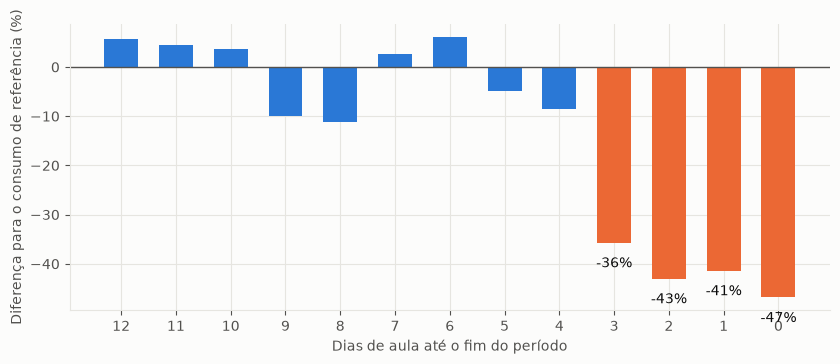

,dias,mediana
dias_ate_fim_bloco,,
0.0,6,0.53
1.0,6,0.59
2.0,8,0.57
3.0,8,0.64
4.0,8,0.92
5.0,8,0.95
6.0,9,1.06
7.0,9,1.03
8.0,7,0.89


In [6]:
blocos = fato[fato["no_escopo"] & fato["tem_consumo"] & fato["bloco"].notna()].copy()
blocos["relativo"] = blocos["consumo"] / blocos.groupby("bloco")["consumo"].transform("median")
perfil = blocos[blocos["dias_ate_fim_bloco"] <= 12].groupby("dias_ate_fim_bloco")["relativo"].agg(dias="size", mediana="median")

fig, ax = plt.subplots(figsize=(8.5, 3.6))
cores = [LARANJA if d <= 3 else AZUL for d in perfil.index]
diferenca = (perfil["mediana"] - 1) * 100
ax.bar(perfil.index, diferenca, width=0.62, color=cores)
ax.axhline(0, color=TEXTO2, linewidth=1)
ax.set_xticks(perfil.index)
ax.invert_xaxis()
ax.set_xlabel("Dias de aula até o fim do período")
ax.set_ylabel("Diferença para o consumo de referência (%)")
for x, y in zip(perfil.index[:4], diferenca[:4]):
    ax.text(x, y - 5, f"{y:.0f}%", ha="center", color=TEXTO)
fig.tight_layout()
fig.savefig(FIGURAS / "02_fim_de_bloco.png", dpi=200)
plt.show()
perfil.round(2)

### A chuva sozinha não identifica os dias atípicos

In [7]:
dias = fato[fato["no_escopo"] & fato["tem_consumo"]].merge(referencia, on="data").dropna(subset=["razao_referencia"])
dias["baixo"] = dias["data"].isin(baixos["data"])
dias["chuva_15mm"] = dias["chuva_mm"] >= 15
print(f"Dias com 15 mm ou mais: {dias['chuva_15mm'].sum()} | dias baixos entre eles: {(dias['chuva_15mm'] & dias['baixo']).sum()}")
print(f"Dias baixos: {dias['baixo'].sum()} | com 15 mm ou mais no dia: {(dias['baixo'] & dias['chuva_15mm']).sum()}")
print(f"Chance de dia baixo com chuva forte: {dias.loc[dias['chuva_15mm'], 'baixo'].mean():.1%}")
print(f"Chance de dia baixo sem chuva forte: {dias.loc[~dias['chuva_15mm'], 'baixo'].mean():.1%}")
dias.groupby(pd.cut(dias["chuva_mm"], [-1, 0, 5, 15, 30, 200]), observed=True)["razao_referencia"].agg(dias="size", mediana="median").round(3)

Dias com 15 mm ou mais: 47 | dias baixos entre eles: 7
Dias baixos: 48 | com 15 mm ou mais no dia: 7
Chance de dia baixo com chuva forte: 14.9%
Chance de dia baixo sem chuva forte: 6.8%


,dias,mediana
chuva_mm,,
"(-1, 0]",265,1.006
"(0, 5]",247,1.013
"(5, 15]",89,0.979
"(15, 30]",43,0.950
"(30, 200]",4,1.012


## 4. Leitura para as próximas etapas

- **Baixa previsível fica nos dados.** Fim e início de bloco e eventos do calendário devem virar atributos, porque são conhecidos antes da sexta-feira de emissão.
- **Dias imprevisíveis ficam na base, mas fora do treino.** São os eventos externos registrados e os dias baixos sem explicação pelo calendário, listados em `silver_dias_classificados`.
- **Toda avaliação será reportada com e sem os atípicos**, para que retirá-los não melhore o resultado artificialmente.